<a href="https://colab.research.google.com/github/dylanhartman65-spec/IS-4487/blob/main/PorscheEVAnalysis(MASTER).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# OLD DATA PREPARATION METHOD

In [ ]:
import pandas as pd

file_path = "/content/drive/MyDrive/GoogleColab/FY-2025-fact-sheet-porsche-ag.xlsx"

excel_file = pd.ExcelFile(file_path)
print(excel_file.sheet_names)

['Cover & Content', '01 - Group EBIT', '02 - Automotive CF', '03 - Sales_deliveries by Region', '04 - Sales_deliveries by Model']


In [ ]:
df_models = pd.read_excel(file_path, sheet_name='03 - Sales_deliveries by Region')

In [ ]:
df_models = pd.read_excel(file_path, sheet_name='04 - Sales_deliveries by Model')

In [ ]:
all_sheets = pd.read_excel(file_path, sheet_name=None)

df_ebit = all_sheets['01 - Group EBIT']
df_models = all_sheets['03 - Sales_deliveries by Region']
df_models = all_sheets['04 - Sales_deliveries by Model']

In [ ]:
df_clean = pd.read_excel(file_path, sheet_name='04 - Sales_deliveries by Model')
df_clean = df_clean.dropna(how='all').dropna(how='all', axis=1)
print(df_clean.iloc[9:20])

                 Unnamed: 0 Unnamed: 2  Unnamed: 4  Unnamed: 6 Unnamed: 8  \
19                Macan BEV       9117       10366       11699      14185   
20                   Taycan       3698        4339        4099       4203   
26                    Units    FY 2025  Q1-Q3 2025  Q1-Q2 2025    Q1 2025   
27           Vehicle sales      265663      198055      135142      64693   
29  Deliveries to customers     279449      212509      146391      71470   
30                      911      51583       37806       25608      11390   
31                      718      18612       15380       10496       4498   
32                  Cayenne      80886       60656       41873      20055   
33                 Panamera      27701       21243       14975       7769   
34                    Macan      84328       64783       45137      23555   
35                Macan ICE      38961       28533       19253       9370   

   Unnamed: 10 Unnamed: 12 Unnamed: 14 Unnamed: 16 Unnamed: 18 Unnamed: 20 

In [ ]:
df_clean = pd.read_excel(file_path, sheet_name='03 - Sales_deliveries by Region')
df_clean = df_clean.dropna(how='all').dropna(how='all', axis=1)
print(df_clean.iloc[9:20])

                          Unnamed: 0 Unnamed: 2 Unnamed: 4 Unnamed: 6  \
24                    Vehicle sales      265663     198055     135142   
26           Deliveries to customers     279449     212509     146391   
27                           Germany      29968      22492      15973   
28  North America (excluding Mexico)      86229      64446      43577   
29       China (including Hong Kong)      41938      32195      21302   
30        Europe (excluding Germany)      66340      50286      35381   
31     Overseas and Emerging Markets      54974      43090      30158   

   Unnamed: 8 Unnamed: 10 Unnamed: 12 Unnamed: 14 Unnamed: 16 Unnamed: 18  \
24      64693      312620      221304      151944       70605      333605   
26      71470      310718      226026      155945       77640      320221   
27       7495       35858       26838       20811       11274       32430   
28      20698       86541       61471       39558       15087       86059   
29       9471       56887     

In [ ]:
df = pd.read_excel("/content/drive/MyDrive/GoogleColab/FY-2025-fact-sheet-porsche-ag.xlsx", sheet_name='03 - Sales_deliveries by Region', header=9)
df = df.dropna(how='all').dropna(how='all', axis=1)
print(df.head())

                         Unnamed: 0 Unnamed: 2 Unnamed: 4 Unnamed: 6  \
0                             Units    Q4 2025    Q3 2025    Q2 2025   
1                    Vehicle sales       67608      62913      70449   
3           Deliveries to customers      66940      66118      74921   
4                           Germany       7476       6519       8478   
5  North America (excluding Mexico)      21783      20869      22879   

  Unnamed: 8 Unnamed: 10 Unnamed: 12 Unnamed: 14 Unnamed: 16 Unnamed: 18  \
0    Q1 2025     Q4 2024     Q3 2024     Q2 2024     Q1 2024     Q4 2023   
1      64693       91316       69360       81339       70605       83413   
3      71470       84692       70081       78305       77640       77499   
4       7495        9020        6027        9537       11274        7616   
5      20698       25070       21913       24471       15087       21572   

  Unnamed: 20 Unnamed: 22 Unnamed: 24 Unnamed: 26 Unnamed: 28 Unnamed: 30  \
0     Q3 2023     Q2 2023     Q1 

In [ ]:
#***PORSCHE FACT SHEET CLEANED AND PREPARED DATASET***

import pandas as pd

# 1. Load raw sheet specifying header row 10 (where Q4 2025, Q3 2025 appear)
excel_path = "/content/drive/MyDrive/GoogleColab/FY-2025-fact-sheet-porsche-ag.xlsx"
df_model = pd.read_excel(excel_path, sheet_name='04 - Sales_deliveries by Model', header=10)

# 2. Slice only the quarterly section (top 8 rows) to avoid cumulative YTD double-counting
df_quarterly = df_model.iloc[:8].copy()

# 3. Drop fully empty rows and spacer columns (Unnamed)
df_quarterly = df_quarterly.dropna(how='all').dropna(how='all', axis=1)
df_quarterly = df_quarterly.loc[:, ~df_quarterly.columns.str.contains('^Unnamed')]

# 4. Rename the first column to 'Model'
df_quarterly = df_quarterly.rename(columns={df_quarterly.columns[0]: 'Model'})

# 5. Filter for target vehicle models
models = ['911', '718', 'Cayenne', 'Panamera', 'Macan ICE', 'Macan BEV', 'Taycan']
df_filtered = df_quarterly[df_quarterly['Model'].isin(models)].copy()

# 6. Reshape from wide to long format (Tidy Data)
df_long = pd.melt(df_filtered, id_vars=['Model'], var_name='Quarter', value_name='Units_Sold')

# 7. Convert sales numbers to numeric data type
df_long['Units_Sold'] = pd.to_numeric(df_long['Units_Sold'], errors='coerce')

# 8. Feature Engineering: Create EV Categorization
df_long['Powertrain'] = df_long['Model'].apply(lambda x: 'BEV' if x in ['Taycan', 'Macan BEV'] else 'ICE/PHEV')

print("=== CLEAN & PREPARED DATASET ===")
print(df_long.head(10))

=== CLEAN & PREPARED DATASET ===
      Model  Quarter  Units_Sold Powertrain
0       911  Q4 2025       13777   ICE/PHEV
1       718  Q4 2025        3232   ICE/PHEV
2   Cayenne  Q4 2025       20230   ICE/PHEV
3  Panamera  Q4 2025        6458   ICE/PHEV
4       911  Q3 2025       12198   ICE/PHEV
5       718  Q3 2025        4884   ICE/PHEV
6   Cayenne  Q3 2025       18783   ICE/PHEV
7  Panamera  Q3 2025        6268   ICE/PHEV
8       911  Q2 2025       14218   ICE/PHEV
9       718  Q2 2025        5998   ICE/PHEV


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("patelris/electric-vehicle-market-and-pricing-dataset-2026")

print("Path to dataset files:", path)

100%|██████████| 82.5k/82.5k [00:00<00:00, 36.2MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/patelris/electric-vehicle-market-and-pricing-dataset-2026/versions/6


In [ ]:
import os
import pandas as pd

# 1. Put the exact folder path provided by kagglehub here
path = "/root/.cache/kagglehub/datasets/patelris/electric-vehicle-market-and-pricing-dataset-2026/versions/6"

# 2. Automatically find the CSV file inside that folder
files = os.listdir(path)
csv_file = [f for f in files if f.endswith('.csv')][0]

# 3. Build the full file path and load it
full_path = os.path.join(path, csv_file)
df_kaggle = pd.read_csv(full_path)

# 4. Run your inspection block safely
print("=== DATASET SHAPE ===")
print(f"Rows: {df_kaggle.shape[0]}, Columns: {df_kaggle.shape[1]}\n")

print("=== COLUMNS & DATA TYPES ===")
print(df_kaggle.dtypes)
print("\n")

print("=== FIRST 5 ROWS ===")
display(df_kaggle.head())

=== DATASET SHAPE ===
Rows: 2000, Columns: 24

=== COLUMNS & DATA TYPES ===
brand                     object
model                     object
year                       int64
variant                   object
price_usd                float64
battery_capacity_kwh     float64
range_miles              float64
charging_speed_kw        float64
acceleration_0_60_mph    float64
top_speed_mph            float64
horsepower               float64
torque_nm                float64
drive_type                object
seating_capacity           int64
body_type                 object
cargo_volume_cubic_ft    float64
weight_kg                float64
safety_rating              int64
autopilot_level            int64
country_of_origin         object
market_segment            object
annual_sales_units         int64
customer_rating          float64
warranty_years             int64
dtype: object


=== FIRST 5 ROWS ===


,brand,model,year,variant,price_usd,battery_capacity_kwh,range_miles,charging_speed_kw,acceleration_0_60_mph,top_speed_mph,...,body_type,cargo_volume_cubic_ft,weight_kg,safety_rating,autopilot_level,country_of_origin,market_segment,annual_sales_units,customer_rating,warranty_years
0,Volkswagen,ID. Buzz,2023,Performance,104880.80,118.7,400.0,234.5,3.04,195.0,...,Truck,54.2,2015.0,4,2,Germany,Luxury,202182,4.00,4
1,Toyota,bZ Compact SUV,2022,Premium,48217.41,58.8,219.0,148.1,5.77,159.0,...,SUV,69.0,1709.0,4,0,Japan,Mid-range,7146,3.56,3
2,GM/Chevrolet,Bolt EV,2024,Premium,49651.12,58.2,225.0,104.9,6.84,148.0,...,Van,77.0,1533.0,4,1,US,Mid-range,16590,3.70,3
3,Kia,Sportage EV,2024,Long Range,38131.56,102.5,349.0,66.5,4.66,176.0,...,SUV,65.8,1935.0,4,2,South Korea,Mid-range,127201,3.81,3
4,Tesla,Model 3,2022,Long Range,144079.87,93.9,314.0,298.5,5.64,165.0,...,SUV,38.3,2229.0,4,2,US,Luxury,196401,3.83,4


In [ ]:
#***KAGGLE CLEANED AND PREPARED DATASET***

import pandas as pd

def clean_dataframe(df):
    """Cleans column headers and structure for a pandas DataFrame."""
    # 1. Drop any accidental index columns (like 'Unnamed: 0')
    df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

    # 2. Standardize column headers: strip whitespace, lowercase, and replace spaces with underscores
    df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_').str.replace('-', '_')

    # 3. Drop completely empty rows or duplicate rows if any exist
    df = df.dropna(how='all').drop_duplicates()

    return df

# Apply the function to your Kaggle datasets
df_kaggle_clean = clean_analytic_df = clean_dataframe(df_kaggle)

print("=== CLEANED COLUMNS ===")
print(df_kaggle_clean.columns.tolist())

=== CLEANED COLUMNS ===
['brand', 'model', 'year', 'variant', 'price_usd', 'battery_capacity_kwh', 'range_miles', 'charging_speed_kw', 'acceleration_0_60_mph', 'top_speed_mph', 'horsepower', 'torque_nm', 'drive_type', 'seating_capacity', 'body_type', 'cargo_volume_cubic_ft', 'weight_kg', 'safety_rating', 'autopilot_level', 'country_of_origin', 'market_segment', 'annual_sales_units', 'customer_rating', 'warranty_years']


In [ ]:
import os
import pandas as pd

df_market = pd.read_csv(full_path)

# 4. Inspect unique market segment categories to verify exact string name
print("=== UNIQUE MARKET SEGMENTS FOUND ===")
print(df_market['market_segment'].unique())

# 5. Filter for rows where 'market_segment' contains 'Luxury' (case-insensitive search)
# Using str.contains handles variations like 'Luxury', 'Luxury EV', or 'High-End Luxury'
df_luxury_only = df_market[
    df_market['market_segment'].astype(str).str.contains('luxury', case=False, na=False)
].copy()

# 6. Sanity check results
print(f"\nOriginal Dataset Shape: {df_market.shape}")
print(f"Filtered Luxury Dataset Shape: {df_luxury_only.shape}")

print("\n=== FIRST 5 LUXURY VEHICLE ROWS ===")
display(df_luxury_only.head())

=== UNIQUE MARKET SEGMENTS FOUND ===
['Luxury' 'Mid-range' 'Premium' 'Budget']

Original Dataset Shape: (2000, 24)
Filtered Luxury Dataset Shape: (495, 24)

=== FIRST 5 LUXURY VEHICLE ROWS ===


,brand,model,year,variant,price_usd,battery_capacity_kwh,range_miles,charging_speed_kw,acceleration_0_60_mph,top_speed_mph,...,body_type,cargo_volume_cubic_ft,weight_kg,safety_rating,autopilot_level,country_of_origin,market_segment,annual_sales_units,customer_rating,warranty_years
0,Volkswagen,ID. Buzz,2023,Performance,104880.80,118.7,400.0,234.5,3.04,195.0,...,Truck,54.2,2015.0,4,2,Germany,Luxury,202182,4.00,4
4,Tesla,Model 3,2022,Long Range,144079.87,93.9,314.0,298.5,5.64,165.0,...,SUV,38.3,2229.0,4,2,US,Luxury,196401,3.83,4
5,Tesla,Model Y,2023,Performance,119590.27,78.3,251.0,334.6,2.84,200.0,...,Hatchback,35.5,1751.0,5,3,US,Luxury,411764,3.67,5
6,Tesla,Model 3,2024,Premium,128427.66,68.6,222.0,201.9,6.68,149.0,...,Coupe,39.3,1500.0,5,2,US,Luxury,213937,3.54,6
7,Mercedes,EQS,2025,Performance,131074.23,82.7,292.0,202.5,2.99,200.0,...,SUV,61.2,2219.0,4,2,Germany,Luxury,48277,4.11,8


In [ ]:
print("=== COLUMNS ===")
print(df_luxury_only.columns.tolist())

print("\n=== SAMPLE DATA ===")
display(df_luxury_only.head(3))

=== COLUMNS ===
['brand', 'model', 'year', 'variant', 'price_usd', 'battery_capacity_kwh', 'range_miles', 'charging_speed_kw', 'acceleration_0_60_mph', 'top_speed_mph', 'horsepower', 'torque_nm', 'drive_type', 'seating_capacity', 'body_type', 'cargo_volume_cubic_ft', 'weight_kg', 'safety_rating', 'autopilot_level', 'country_of_origin', 'market_segment', 'annual_sales_units', 'customer_rating', 'warranty_years']

=== SAMPLE DATA ===


,brand,model,year,variant,price_usd,battery_capacity_kwh,range_miles,charging_speed_kw,acceleration_0_60_mph,top_speed_mph,...,body_type,cargo_volume_cubic_ft,weight_kg,safety_rating,autopilot_level,country_of_origin,market_segment,annual_sales_units,customer_rating,warranty_years
0,Volkswagen,ID. Buzz,2023,Performance,104880.80,118.7,400.0,234.5,3.04,195.0,...,Truck,54.2,2015.0,4,2,Germany,Luxury,202182,4.00,4
4,Tesla,Model 3,2022,Long Range,144079.87,93.9,314.0,298.5,5.64,165.0,...,SUV,38.3,2229.0,4,2,US,Luxury,196401,3.83,4
5,Tesla,Model Y,2023,Performance,119590.27,78.3,251.0,334.6,2.84,200.0,...,Hatchback,35.5,1751.0,5,3,US,Luxury,411764,3.67,5


In [ ]:
import pandas as pd
import numpy as np

# 1. One-Hot Encode 'drive_type' into binary indicators (drive_AWD, drive_RWD, drive_FWD)
df_luxury_encoded = pd.get_dummies(df_luxury_only, columns=['drive_type'], prefix='drive', drop_first=False)

# 2. Select numeric feature columns that exist in your dataset
possible_features = [
    'msrp', 'price', 'horsepower', 'hp', 'battery_capacity_kwh',
    'battery_kwh', 'range_km', 'range_miles', 'charging_speed_kw',
    'drive_AWD', 'drive_RWD', 'drive_FWD', 'drive_type_AWD', 'drive_type_RWD', 'drive_type_FWD'
]

feature_cols = [col for col in possible_features if col in df_luxury_encoded.columns]

print("=== VERIFIED MODEL FEATURES ===")
print(feature_cols)

=== VERIFIED MODEL FEATURES ===
['horsepower', 'battery_capacity_kwh', 'range_miles', 'charging_speed_kw', 'drive_AWD', 'drive_RWD', 'drive_FWD']


/tmp/ipykernel_1260/3910958349.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')


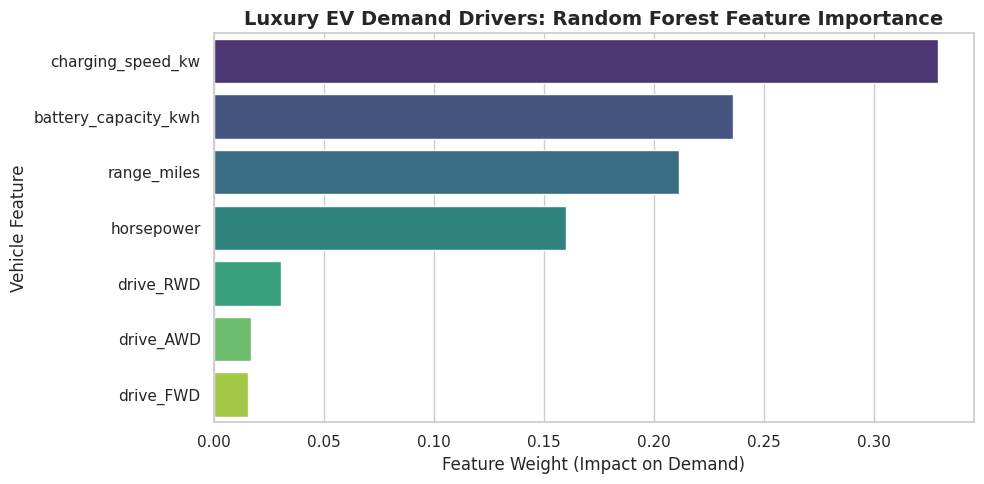

In [ ]:
#***TRAINED KAGGLE LUXURY EV DATASET***

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# 1. Identify your target variable column (e.g., 'units_sold', 'sales', or 'price')
target_col = [c for c in df_luxury_encoded.columns if c in ['units_sold', 'sales', 'sales_volume', 'deliveries']][0] if any(c in df_luxury_encoded.columns for c in ['units_sold', 'sales', 'sales_volume', 'deliveries']) else df_luxury_encoded.select_dtypes(include=[np.number]).columns[0]

X = df_luxury_encoded[feature_cols].fillna(0)
y = df_luxury_encoded[target_col]

# 2. Split dataset into Training (80%) and Testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Train Random Forest Model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 4. Extract and visualize feature importances
importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))
sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')

plt.title('Luxury EV Demand Drivers: Random Forest Feature Importance', fontsize=14, fontweight='bold')
plt.xlabel('Feature Weight (Impact on Demand)', fontsize=12)
plt.ylabel('Vehicle Feature', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
# Predict on testing set
y_pred = rf_model.predict(X_test)

# Calculate metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"=== MODEL EVALUATION METRICS ===")
print(f"R² Score: {r2:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")

=== MODEL EVALUATION METRICS ===
R² Score: -0.1628
Mean Absolute Error (MAE): 1.19
Root Mean Squared Error (RMSE): 1.53


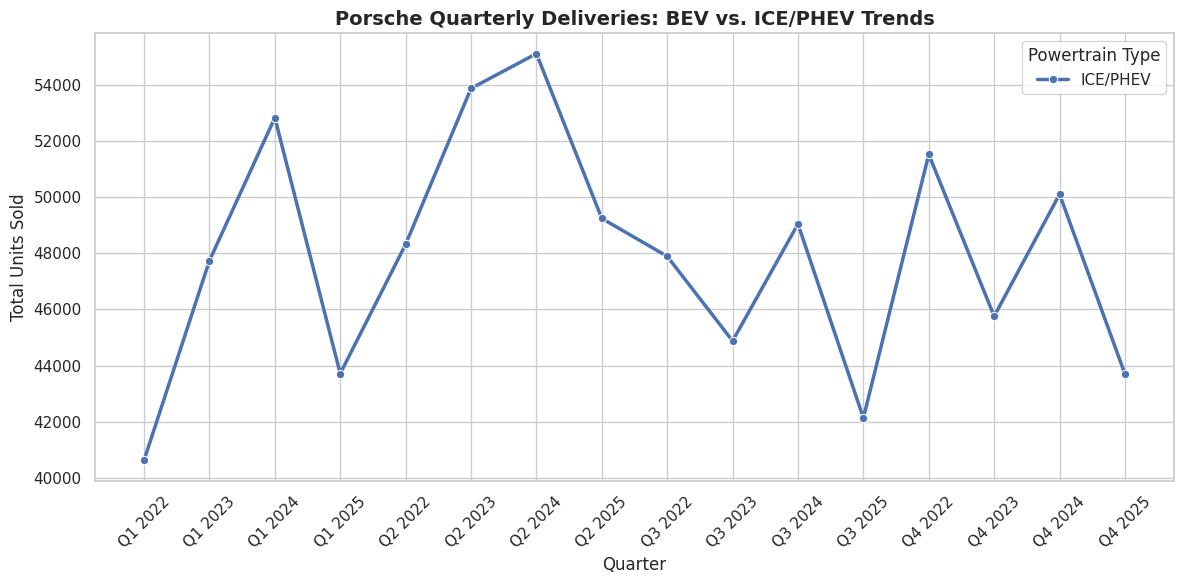

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load and prepare the Porsche quarterly data
excel_path = "/content/drive/MyDrive/GoogleColab/FY-2025-fact-sheet-porsche-ag.xlsx"
df_model = pd.read_excel(excel_path, sheet_name='04 - Sales_deliveries by Model', header=10)

# Slice quarterly rows, clean columns, and rename model header
df_quarterly = df_model.iloc[:8].copy()
df_quarterly = df_quarterly.dropna(how='all').dropna(how='all', axis=1)
df_quarterly = df_quarterly.loc[:, ~df_quarterly.columns.str.contains('^Unnamed')]
df_quarterly = df_quarterly.rename(columns={df_quarterly.columns[0]: 'Model'})

# Filter for relevant models and melt into long format
models = ['911', '718', 'Cayenne', 'Panamera', 'Macan ICE', 'Macan BEV', 'Taycan']
df_filtered = df_quarterly[df_quarterly['Model'].isin(models)].copy()
df_long_quarterly = pd.melt(df_filtered, id_vars=['Model'], var_name='Quarter', value_name='Units_Sold')

# Clean numbers and assign powertrain categories
df_long_quarterly['Units_Sold'] = pd.to_numeric(df_long_quarterly['Units_Sold'], errors='coerce')
df_long_quarterly['Powertrain'] = df_long_quarterly['Model'].apply(lambda x: 'BEV' if x in ['Taycan', 'Macan BEV'] else 'ICE/PHEV')

# 2. Aggregate sales by Quarter and Powertrain for visualization
porsche_trends = df_long_quarterly.groupby(['Quarter', 'Powertrain'])['Units_Sold'].sum().reset_index()

# 3. Generate the trend visualization
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=porsche_trends,
    x='Quarter',
    y='Units_Sold',
    hue='Powertrain',
    marker='o',
    linewidth=2.5
)

plt.title('Porsche Quarterly Deliveries: BEV vs. ICE/PHEV Trends', fontsize=14, fontweight='bold')
plt.xlabel('Quarter', fontsize=12)
plt.ylabel('Total Units Sold', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Powertrain Type')
plt.tight_layout()
plt.show()

# *NEW DATA PREPARATION METHOD*

In [ ]:
print("=== PORSCHE DATAFRAME ===")
print("Columns:", df_long_quarterly.columns.tolist())
display(df_long_quarterly.head(3))

print("\n=== KAGGLE LUXURY DATAFRAME ===")
print("Columns:", df_luxury_encoded.columns.tolist())
display(df_luxury_encoded.head(3))

=== PORSCHE DATAFRAME ===
Columns: ['Model', 'Quarter', 'Units_Sold', 'Powertrain', 'Year']


,Model,Quarter,Units_Sold,Powertrain,Year
0,911,4,13777,ICE/PHEV,2025
1,718,4,3232,ICE/PHEV,2025
2,Cayenne,4,20230,ICE/PHEV,2025



=== KAGGLE LUXURY DATAFRAME ===
Columns: ['year', 'horsepower', 'battery_capacity_kwh', 'range_miles', 'charging_speed_kw', 'drive_AWD', 'drive_RWD', 'drive_FWD']


,year,horsepower,battery_capacity_kwh,range_miles,charging_speed_kw,drive_AWD,drive_RWD,drive_FWD


In [ ]:
!pip install pdfplumber

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 20.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 34.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 69.8 MB/s  0:00:00
  Attempting uninstall: Pillow
    Found existing installation: pillow 11.3.0
    Uninstalling pillow-11.3.0:
      Successfully uninstalled pillow-11.3.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pdfplumber]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [ ]:
# Extracted government policies from PDF

import pandas as pd
import pdfplumber

all_rows = []

# Open the PDF and loop through every page to extract tables
with pdfplumber.open("/content/drive/MyDrive/GoogleColab/GEVO2026PolicyExplorer.pdf") as pdf:
  for page in pdf.pages:
    tables = page.extract_tables()
    for table in tables:
      for row in table:
        all_rows.append(row)

# Convert to DataFrame (assuming the first row extracted is the header)
df_policies_raw = pd.DataFrame(all_rows[1:], columns=all_rows[0])

# Clean up newline characters (\n) that PDFs often leave inside cells
df_policies_raw = df_policies_raw.replace(r"\n", " ", regex=True)

# Drop duplicate header rows that repeat at the top of every PDF page
df_policies = df_policies_raw[
    df_policies_raw.iloc[:, 0] != df_policies_raw.columns[0]
].copy()

print(f"Extracted {len(df_policies)} policy records!")
display(df_policies.head(5))

Extracted 860 policy records!


,Global EV Outlook 2026 Policy Explorer
0,Region Country Policy Level Policy Type Key po...
1,Through the national Action Plan for Energy an...
2,Europe Albania National Legislation Total VAT ...
3,Africa Angola National Legislation 50% reducti...
4,Antigua and Announced Central and South Americ...


In [ ]:
header_idx = 0  # Change to 1 if the headers are on row index 1

# 1. Clean the header labels and assign them as columns
new_headers = (
    df_policies.iloc[header_idx]
    .fillna("")
    .astype(str)
    .str.replace("\n", " ", regex=False)
    .str.strip()
)
df_policies_clean = df_policies.iloc[header_idx + 1 :].copy()
df_policies_clean.columns = new_headers

# 2. Drop any empty/unnamed columns created by merged banner cells
df_policies_clean = df_policies_clean.loc[
    :, df_policies_clean.columns != ""
].copy()

# 3. Remove repeated header rows that PDFs often repeat at the top of each page
first_col = df_policies_clean.columns[0]
df_policies_clean = df_policies_clean[
    df_policies_clean[first_col].astype(str).str.strip() != first_col
].reset_index(drop=True)

print("Fixed columns:", df_policies_clean.columns.tolist())
display(df_policies_clean.head(5))

Fixed columns: ['Region Country Policy Level Policy Type Key policy measures and targets Category Year Source']


,Region Country Policy Level Policy Type Key policy measures and targets Category Year Source
0,Through the national Action Plan for Energy an...
1,Europe Albania National Legislation Total VAT ...
2,Africa Angola National Legislation 50% reducti...
3,Antigua and Announced Central and South Americ...
4,Antigua and Central and South America Barbuda ...


In [ ]:
import re
import pandas as pd
import pdfplumber

# Known IEA Global EV Policy Explorer controlled vocabularies
KNOWN_REGIONS = {
    "Europe", "North America", "Asia Pacific", "Central and South America",
    "Middle East", "Africa", "Eurasia"
}

KNOWN_COUNTRIES = {
    "China", "People's Republic of China", "United States", "Canada", "Mexico",
    "Germany", "France", "United Kingdom", "Norway", "Sweden", "Netherlands",
    "Italy", "Spain", "Belgium", "Austria", "Denmark", "Finland", "Poland",
    "Portugal", "Switzerland", "Greece", "Ireland", "Hungary", "Czech Republic",
    "Japan", "Korea", "India", "Brazil", "Australia", "New Zealand", "Thailand",
    "Indonesia", "South Africa", "Chile", "Colombia", "European Union"
}

POLICY_TYPES = r"(Legislation|Regulation|Subsidy|Taxation|Announced target|Target|Proposal|Ambition)"
CATEGORIES   = r"\b(LDV|M/HDV|EVSE|2/3W|Bus|Manufacturing|Taxation|Multiple)\b"

records = []
current_region = None
current_country = None

with pdfplumber.open("/content/drive/MyDrive/GoogleColab/GEVO2026PolicyExplorer.pdf") as pdf:
    for page in pdf.pages:
        text = page.extract_text() or ""
        for raw_line in text.split("\n"):
            line = raw_line.strip()
            if not line:
                continue

            # 1. Track Region and Country section headers as the parser moves down the page
            if line in KNOWN_REGIONS:
                current_region = line
                continue
            if line in KNOWN_COUNTRIES:
                current_country = line
                if current_country in {"China", "People's Republic of China"}:
                    current_region = "China"
                elif current_country in {"United States", "Canada", "Mexico"}:
                    current_region = "North America"
                elif current_country in {"Germany", "France", "United Kingdom", "Norway", "Sweden", "Netherlands", "Italy", "Spain", "European Union"}:
                    current_region = "Europe"
                continue

            # 2. Detect lines/entries that contain structured policy metadata (Year + Policy Type or Category)
            year_match = re.search(r"\b(201\d|202\d)\b", line)
            ptype_match = re.search(POLICY_TYPES, line, flags=re.IGNORECASE)
            cat_matches = re.findall(CATEGORIES, line)

            if year_match and (ptype_match or cat_matches):
                records.append({
                    "Region": current_region,
                    "Country": current_country,
                    "Policy_Type": ptype_match.group(1).title() if ptype_match else None,
                    "Category": ", ".join(dict.fromkeys(cat_matches)) if cat_matches else None,
                    "Year": int(year_match.group(1)),
                    "Raw_Line": line
                })

df_policies_structured = pd.DataFrame(records)
print(f"Parsed {len(df_policies_structured)} structured policy entries!")
display(df_policies_structured.head(15))

Parsed 834 structured policy entries!


,Region,Country,Policy_Type,Category,Year,Raw_Line
0,None,None,Proposal,"EVSE, Multiple",2025,Europe Albania National Proposal install 200 t...
1,None,None,Legislation,"Taxation, Multiple",2020,Europe Albania National Legislation Total VAT ...
2,None,None,Legislation,"Multiple, Taxation",2022,Africa Angola National Legislation 50% reducti...
3,None,None,Target,Multiple,2021,Central and South America Barbuda National tar...
4,None,None,Legislation,Taxation,2024,Central and South America Barbuda National Leg...
5,None,None,Proposal,Manufacturing,2021,Central and South America Argentina National P...
6,None,None,Target,LDV,2020,Central and South America Argentina Subnationa...
7,None,None,Target,Bus,2020,Central and South America Argentina Subnationa...
8,None,None,Proposal,Multiple,2021,Central and South America Argentina National P...
9,None,None,Proposal,Manufacturing,2024,Central and South America Argentina National P...


In [ ]:
# Inspect sample lines that had None for Country or Region
missing_geo = df_policies_structured[
    df_policies_structured["Country"].isna()
    | (df_policies_structured["Country"] == "None")
]
print(f"Rows missing Country/Region: {len(missing_geo)}")
for line in missing_geo["Raw_Line"].head(15):
  print(" ->", line)

Rows missing Country/Region: 834
 -> Europe Albania National Proposal install 200 to 300 charging stations by 2025 throughout the country. EVSE, Multiple 2021 Government of Albania
 -> Europe Albania National Legislation Total VAT exemption for imports of EVs. Taxation, Multiple 2020 Government of Albania
 -> Africa Angola National Legislation 50% reduction of both import duty and vehicle tax for EVs. Multiple, Taxation 2022 Government of Angola
 -> Central and South America Barbuda National target Transition the government fleet to all-electric by 2035. Multiple 2021 Government of Antigua and Barbuda
 -> Central and South America Barbuda National Legislation Waiver for import duties for electric vehicles. Taxation 2024 Government of Antigua and Barbuda
 -> Central and South America Argentina National Proposal 2 500 jobs in battery manufacturing by 2030. Manufacturing 2021 Government of Argentina
 -> Central and South America Argentina Subnational target Buenos Aires: 30% low-emission 

In [ ]:
import re
import pandas as pd
import pdfplumber

COUNTRY_TO_REGION = {
    "china": "China",
    "people's republic of china": "China",
    "united states": "North America",
    "usa": "North America",
    "canada": "North America",
    "mexico": "North America",
    "germany": "Europe",
    "france": "Europe",
    "united kingdom": "Europe",
    "uk": "Europe",
    "norway": "Europe",
    "sweden": "Europe",
    "netherlands": "Europe",
    "italy": "Europe",
    "spain": "Europe",
    "european union": "Europe",
    "eu": "Europe",
    "japan": "Asia Pacific",
    "korea": "Asia Pacific",
    "south korea": "Asia Pacific",
    "india": "Asia Pacific",
    "australia": "Asia Pacific",
    "brazil": "Central and South America",
    "chile": "Central and South America",
}

REGION_PATTERNS = [
    ("North America", r"\bnorth america\b"),
    ("Europe", r"\beurope\b"),
    ("China", r"\b(people's republic of )?china\b"),
    ("Asia Pacific", r"\basia[- ]pacific\b"),
    ("Central and South America", r"\b(central and )?south america|latin america\b"),
    ("Middle East", r"\bmiddle east\b"),
    ("Africa", r"\bafrica\b"),
    ("Eurasia", r"\beurasia\b"),
]

POLICY_TYPES = r"\b(Legislation|Regulation|Subsidy|Taxation|Announced target|Target|Proposal|Ambition)\b"
CATEGORIES = r"\b(LDV|M/HDV|EVSE|2/3W|Bus|Manufacturing|Taxation|Multiple)\b"


def extract_country_and_region(line: str, current_region: str | None, current_country: str | None):
  low = re.sub(r"\s+", " ", line.lower()).strip()

  matched_country = current_country
  matched_region = current_region

  # 1. Check if a known country name appears on this line
  for c_key, reg_bucket in COUNTRY_TO_REGION.items():
    if re.search(rf"\b{re.escape(c_key)}\b", low):
      matched_country = c_key.title() if c_key != "usa" else "United States"
      matched_region = reg_bucket
      break

  # 2. Check if a region label appears on this line
  for reg_label, pattern in REGION_PATTERNS:
    if re.search(pattern, low):
      matched_region = reg_label
      break

  return matched_region, matched_country


records = []
current_region = None
current_country = None

with pdfplumber.open("/content/drive/MyDrive/GoogleColab/GEVO2026PolicyExplorer.pdf") as pdf:
  for page in pdf.pages:
    # layout=True often preserves horizontal row grouping better than default extraction
    text = page.extract_text(layout=True) or page.extract_text() or ""
    for raw_line in text.split("\n"):
      line = re.sub(r"\s+", " ", raw_line).strip()
      if not line:
        continue

      current_region, current_country = extract_country_and_region(
          line, current_region, current_country
      )

      year_match = re.search(r"\b(201\d|202\d)\b", line)
      ptype_match = re.search(POLICY_TYPES, line, flags=re.IGNORECASE)
      cat_matches = re.findall(CATEGORIES, line)

      if year_match and (ptype_match or cat_matches):
        records.append({
            "Region": current_region,
            "Country": current_country,
            "Policy_Type": ptype_match.group(1).title() if ptype_match else None,
            "Category": ", ".join(dict.fromkeys(cat_matches)) if cat_matches else None,
            "Year": int(year_match.group(1)),
            "Raw_Line": line,
        })

df_policies_structured = pd.DataFrame(records)

# Forward-fill Region within sequential rows if a country header didn't restate the region
df_policies_structured["Region"] = df_policies_structured["Region"].ffill()

print(f"Total parsed rows: {len(df_policies_structured)}")
print("Null/None counts:\n", df_policies_structured[["Region", "Country"]].isna().sum())
display(df_policies_structured.head(15))

Total parsed rows: 825
Null/None counts:
 Region      0
Country    21
dtype: int64


,Region,Country,Policy_Type,Category,Year,Raw_Line
0,Europe,None,Proposal,"EVSE, Multiple",2025,Europe Albania National Proposal install 200 t...
1,Europe,None,Legislation,"Taxation, Multiple",2020,Europe Albania National Legislation Total VAT ...
2,Africa,None,Legislation,"Multiple, Taxation",2022,Africa Angola National Legislation 50% reducti...
3,Central and South America,None,Target,Multiple,2021,Central and South America Barbuda National tar...
4,Central and South America,None,Legislation,Taxation,2024,Central and South America Barbuda National Leg...
5,Central and South America,None,Proposal,Manufacturing,2021,Central and South America Argentina National P...
6,Central and South America,None,Target,LDV,2020,Central and South America Argentina Subnationa...
7,Central and South America,None,Target,Bus,2020,Central and South America Argentina Subnationa...
8,Central and South America,None,Proposal,Multiple,2021,Central and South America Argentina National P...
9,Central and South America,None,Proposal,Manufacturing,2024,Central and South America Argentina National P...


In [ ]:
none_country = df_policies_structured[
    df_policies_structured["Country"].isna()
    | (df_policies_structured["Country"].astype(str).str.lower() == "none")
]

print(f"Rows with 'None' Country: {len(none_country)}")
display(none_country[["Region", "Country", "Year", "Raw_Line"]].head(20))

Rows with 'None' Country: 21


,Region,Country,Year,Raw_Line
0,Europe,None,2025,Europe Albania National Proposal install 200 t...
1,Europe,None,2020,Europe Albania National Legislation Total VAT ...
2,Africa,None,2022,Africa Angola National Legislation 50% reducti...
3,Central and South America,None,2021,Central and South America Barbuda National tar...
4,Central and South America,None,2024,Central and South America Barbuda National Leg...
5,Central and South America,None,2021,Central and South America Argentina National P...
6,Central and South America,None,2020,Central and South America Argentina Subnationa...
7,Central and South America,None,2020,Central and South America Argentina Subnationa...
8,Central and South America,None,2021,Central and South America Argentina National P...
9,Central and South America,None,2024,Central and South America Argentina National P...


In [100]:
# ***ORGANIZED POLICY EXPLORER DATA FROM IEA***


import re
import pandas as pd
import pdfplumber

CORE_COUNTRIES = [
    "People's Republic of China", "China",
    "United States", "U.S.", "USA", "Canada", "Mexico",
    "Germany", "France", "United Kingdom", "UK", "Norway", "Sweden",
    "Netherlands", "The Netherlands", "Italy", "Spain", "Belgium",
    "Austria", "Denmark", "Finland", "Poland", "Portugal", "Switzerland",
    "Greece", "Ireland", "Hungary", "Czech Republic", "Czechia",
    "European Union", "EU"
]

REGION_PATTERNS = [
    ("North America", r"\bnorth america\b"),
    ("Europe", r"\beurope\b"),
    ("China", r"\b(people's republic of )?china\b"),
    ("Asia Pacific", r"\basia[- ]pacific\b"),
    ("Central and South America", r"\b(central and )?south america|latin america\b"),
    ("Middle East", r"\bmiddle east\b"),
    ("Africa", r"\bafrica\b"),
    ("Eurasia", r"\beurasia\b"),
]

POLICY_TYPES = r"\b(Legislation|Regulation|Subsidy|Taxation|Announced target|Target|Proposal|Ambition)\b"
CATEGORIES   = r"\b(LDV|M/HDV|EVSE|2/3W|Bus|Manufacturing|Taxation|Multiple)\b"


def normalize_country_name(raw_name: str) -> str:
    low = raw_name.lower().strip()
    if "china" in low:
        return "China"
    if low in {"u.s.", "usa", "united states"}:
        return "United States"
    if low in {"uk", "united kingdom"}:
        return "United Kingdom"
    if low in {"eu", "european union"}:
        return "European Union"
    if "netherlands" in low:
        return "Netherlands"
    if low in {"czechia", "czech republic"}:
        return "Czech Republic"
    return raw_name.strip().title()


def detect_country(line: str) -> str | None:
    # Check exact/word-boundary matches against known countries (longest names first)
    for cname in sorted(CORE_COUNTRIES, key=len, reverse=True):
        if re.search(rf"(?<!\w){re.escape(cname)}(?!\w)", line, flags=re.IGNORECASE):
            return normalize_country_name(cname)

    # Fallback: short title-case/all-caps standalone header line (1-3 words, no digits or policy keywords)
    cleaned = re.sub(r"[^A-Za-z\s'-]", "", line).strip()
    words = cleaned.split()
    if (
        1 <= len(words) <= 3
        and len(line) <= 35
        and not re.search(r"\d", line)
        and not re.search(POLICY_TYPES, line, flags=re.IGNORECASE)
        and not re.search(CATEGORIES, line)
        and not any(re.search(pat, line.lower()) for _, pat in REGION_PATTERNS)
    ):
        return normalize_country_name(cleaned)

    return None


records = []
current_region = None
current_country = None

with pdfplumber.open("/content/drive/MyDrive/GoogleColab/GEVO2026PolicyExplorer.pdf") as pdf:
    for page in pdf.pages:
        text = page.extract_text(layout=True) or page.extract_text() or ""
        for raw_line in text.split("\n"):
            line = re.sub(r"\s+", " ", raw_line).strip()
            if not line:
                continue

            # Update region if present; if region changes, clear stale country until a new one appears
            for reg_label, pat in REGION_PATTERNS:
                if re.search(pat, line.lower()):
                    if current_region != reg_label:
                        current_region = reg_label
                        current_country = None
                    break

            # Update country if present on this line
            found_country = detect_country(line)
            if found_country:
                current_country = found_country
                if found_country == "China":
                    current_region = "China"
                elif found_country in {"United States", "Canada", "Mexico"}:
                    current_region = "North America"
                elif current_region is None:
                    current_region = "Europe"

            year_match = re.search(r"\b(201\d|202\d)\b", line)
            ptype_match = re.search(POLICY_TYPES, line, flags=re.IGNORECASE)
            cat_matches = re.findall(CATEGORIES, line)

            if year_match and (ptype_match or cat_matches):
                records.append({
                    "Region": current_region,
                    "Country": current_country,
                    "Policy_Type": ptype_match.group(1).title() if ptype_match else None,
                    "Category": ", ".join(dict.fromkeys(cat_matches)) if cat_matches else None,
                    "Year": int(year_match.group(1)),
                    "Raw_Line": line
                })

df_policies_structured = pd.DataFrame(records)

# Replace literal string "None" with real NaN, then forward-fill Region and Country within groups
df_policies_structured["Country"] = df_policies_structured["Country"].replace(["None", "none", ""], pd.NA)
df_policies_structured["Region"] = df_policies_structured["Region"].replace(["None", "none", ""], pd.NA).ffill()
df_policies_structured["Country"] = df_policies_structured.groupby("Region")["Country"].ffill()

print(df_policies_structured[["Region", "Country"]].value_counts(dropna=False).head(20))
display(df_policies_structured.head(15))

Region                     Country       
Asia Pacific               Announced         128
Africa                     Announced         114
Central and South America  Announced          95
China                      China              47
Europe                     European Union     39
                           Italy              30
                           Announced          29
                           Belgium            23
Eurasia                    Announced          22
North America              United States      22
Europe                     France             21
North America              Canada             21
Eurasia                    NaN                20
Europe                     United Kingdom     18
                           Netherlands        15
                           Austria            15
                           Poland             14
Middle East                NaN                13
Europe                     Ireland            12
North America              

,Region,Country,Policy_Type,Category,Year,Raw_Line
0,Europe,NaN,Proposal,"EVSE, Multiple",2025,Europe Albania National Proposal install 200 t...
1,Europe,NaN,Legislation,"Taxation, Multiple",2020,Europe Albania National Legislation Total VAT ...
2,Africa,NaN,Legislation,"Multiple, Taxation",2022,Africa Angola National Legislation 50% reducti...
3,Central and South America,NaN,Target,Multiple,2021,Central and South America Barbuda National tar...
4,Central and South America,Antigua And,Legislation,Taxation,2024,Central and South America Barbuda National Leg...
5,Central and South America,Antigua And,Proposal,Manufacturing,2021,Central and South America Argentina National P...
6,Central and South America,Announced,Target,LDV,2020,Central and South America Argentina Subnationa...
7,Central and South America,Announced,Target,Bus,2020,Central and South America Argentina Subnationa...
8,Central and South America,Announced,Proposal,Multiple,2021,Central and South America Argentina National P...
9,Central and South America,Announced,Proposal,Manufacturing,2024,Central and South America Argentina National P...


In [ ]:
import pdfplumber

new_pdf_path = "/content/drive/MyDrive/GoogleColab/KBB_data.pdf"  # Update with your new filename

with pdfplumber.open(new_pdf_path) as pdf:
  print(f"Total pages: {len(pdf.pages)}")

  # Check page 1 (or page 2/3 if page 1 is a cover/summary)
  sample_page = pdf.pages[1] if len(pdf.pages) > 1 else pdf.pages[0]
  tables_found = sample_page.extract_tables()
  print(f"Tables detected on sample page: {len(tables_found)}")

  print("\n--- First 25 text lines on sample page ---")
  for idx, line in enumerate((sample_page.extract_text() or "").split("\n")[:25]):
    print(f"{idx:02d}: {line}")

Total pages: 4
Tables detected on sample page: 2

--- First 25 text lines on sample page ---
00: ELECTRIC VEHICLE (BRAND)
01: Q3 Sales YTD Sales Segment Share
02: 2026 2025 YOY 2026 2025 YOY Q3 YTD
03: Audi 1,039 18,071 -94.3% 2,736 29,630 -90.8% 0.4% 0.4%
04: BMW 4,945 10,294 -52.0% 15,735 34,926 -54.9% 1.9% 2.2%
05: Cadillac 12,358 18,383 -32.8% 34,125 38,151 -10.6% 4.6% 4.7%
06: Chevrolet 10,031 39,498 -74.6% 38,298 87,137 -56.0% 3.8% 5.2%
07: Dodge 233 2,776 -91.6% 767 7,075 -89.2% 0.1% 0.1%
08: Ford 6,047 30,612 -80.2% 22,653 69,600 -67.5% 2.3% 3.1%
09: Genesis 494 1,220 -59.5% 1,054 3,670 -71.3% 0.2% 0.1%
10: GMC 3,084 8,620 -64.2% 9,729 19,380 -49.8% 1.2% 1.3%
11: Honda 4,882 20,236 -75.9% 13,289 36,553 -63.6% 1.8% 1.8%
12: Hyundai 12,185 28,780 -57.7% 39,121 57,239 -31.7% 4.6% 5.4%
13: Jeep 181 4,173 -95.7% 599 10,436 -94.3% 0.1% 0.1%
14: Kia 9,575 14,794 -35.3% 22,202 28,528 -22.2% 3.6% 3.0%
15: Lexus 4,483 1,561 187.2% 12,678 5,340 137.4% 1.7% 1.7%
16: Lucid 2,708 3,181 -14.9

In [99]:
#***CLEANED AND PREPARED KBB DATASET***



import pdfplumber
import pandas as pd

pdf_path = "/content/drive/MyDrive/GoogleColab/KBB_data.pdf"
all_data_rows = []

with pdfplumber.open(pdf_path) as pdf:
    for page in pdf.pages:
        tables = page.extract_tables()
        for table in tables:
            if table:
                for row in table:
                    # Filter out empty or completely null rows
                    if row and any(item is not None for item in row):
                        all_data_rows.append(row)

# Create DataFrame
if len(all_data_rows) > 1:
    columns = ['Brand', 'Q3_Sales_2026', 'Q3_Sales_2025', 'Q3_YOY', 'YTD_Sales_2026', 'YTD_Sales_2025', 'YTD_YOY', 'Q3_Share', 'YTD_Share']

    clean_rows = []
    for r in all_data_rows:
        # Ensure we are dealing with a list and cast contents to string safely
        if not isinstance(r, list):
            continue

        row_strs = [str(item) if item is not None else "" for item in r]

        # Skip header rows
        if any("Q3 Sales" in s or "2026" in s for s in row_strs) or (len(row_strs) > 0 and "ELECTRIC" in row_strs[0]):
            continue

        # Pad or truncate row to fit columns if needed
        if len(row_strs) < len(columns):
            row_strs = row_strs + [None] * (len(columns) - len(row_strs))
        elif len(row_strs) > len(columns):
            row_strs = row_strs[:len(columns)]
        clean_rows.append(row_strs)

    df_kbb_raw = pd.DataFrame(clean_rows, columns=columns)
    # Drop completely null or title-based rows
    df_kbb_raw = df_kbb_raw.dropna(subset=['Brand'])
    df_kbb_raw = df_kbb_raw[df_kbb_raw['Brand'].str.strip() != ""]

    # Remove unnecessary columns
    drop_cols = ['Q3_Sales_2026', 'Q3_Sales_2025', 'Q3_YOY', 'YTD_Sales_2026', 'YTD_YOY', 'Q3_Share', 'YTD_Share']
    df_kbb_raw = df_kbb_raw.drop(columns=drop_cols, errors='ignore')

    # Rename 'YTD_Sales_2025' to 'Sales' and add 'Year' as '2025'
    df_kbb_raw = df_kbb_raw.rename(columns={'YTD_Sales_2025': 'Sales'})
    df_kbb_raw['Year'] = "2025"

    print("=== EXTRACTED KBB DATA (CLEANED & RE-FORMATTED) ===")
    print(f"Shape: {df_kbb_raw.shape}")
    display(df_kbb_raw.head(15))
else:
    print("No table data could be extracted.")

=== EXTRACTED KBB DATA (CLEANED & RE-FORMATTED) ===
Shape: (106, 3)


,Brand,Sales,Year
2,Audi,"29,630",2025
3,BMW,"34,926",2025
4,Cadillac,"38,151",2025
5,Chevrolet,"87,137",2025
6,Dodge,"7,075",2025
7,Ford,"69,600",2025
8,Genesis,"3,670",2025
9,GMC,"19,380",2025
10,Honda,"36,553",2025
11,Hyundai,"57,239",2025


In [98]:
#***CLEANED AND PREPARED PORSCHE FACT SHEET DATASET***


import pandas as pd
import numpy as np
import re

file_path = "/content/drive/MyDrive/GoogleColab/FY-2025-fact-sheet-porsche-ag.xlsx"

# 1. Load sheets using header=10
df_regions = pd.read_excel(file_path, sheet_name='03 - Sales_deliveries by Region', header=10)
df_models = pd.read_excel(file_path, sheet_name='04 - Sales_deliveries by Model', header=10)

# 2. Transpose the DataFrames
df_regions_transposed = df_regions.T
df_models_transposed = df_models.T

# 3. Helper function to set columns, resolve quarterly/annual duplicates, clean rows/columns, extract Year/Quarter, and reorder
def clean_transposed_dataframe(df):
    # Extract first row as the raw headers
    raw_headers = df.iloc[0].astype(str).str.strip().tolist()
    df = df[1:]

    # Resolve duplicates by appending '- Quarterly' to the first and '- Annual' to the second occurrence
    seen = {}
    new_headers = []
    for col in raw_headers:
        if col in ['nan', 'None', 'NaN'] or pd.isna(col):
            new_headers.append(np.nan)
        elif col == 'Units':
            new_headers.append('Units')
        else:
            if col not in seen:
                seen[col] = 1
                new_headers.append(f"{col} - Quarterly")
            else:
                new_headers.append(f"{col} - Annual")

    df.columns = new_headers

    # Filter out columns where name is NaN, null, or contains 'Units'
    valid_cols = [col for col in df.columns if pd.notna(col) and str(col).strip().lower() != 'units' and str(col) != 'nan']
    df = df[valid_cols]

    # Reset index and rename index column to 'Quarter'
    df = df.rename_axis('Quarter').reset_index()

    # Filter out rows where the 'Quarter' column has 'Unnamed' or NaN
    df = df[df['Quarter'].notna() & ~df['Quarter'].astype(str).str.contains('Unnamed', case=False)]

    # Drop 'Vehicle sales', 'Deliveries to customers', and 'Overseas and Emerging Markets' columns if present
    phrases_to_drop = ['vehicle sales', 'deliveries to customers', 'overseas and emerging markets']
    cols_to_drop = [c for c in df.columns if any(phrase in str(c).lower() for phrase in phrases_to_drop)]
    df = df.drop(columns=cols_to_drop, errors='ignore')

    # Extract Year and numerical Quarter
    df['Year'] = df['Quarter'].astype(str).str.extract(r'(\d{4})').astype(float).astype('Int64')
    df['Quarter'] = df['Quarter'].astype(str).str.extract(r'[qQ](\d)').astype(float).astype('Int64')

    # Drop rows that don't match a quarterly structure
    df = df.dropna(subset=['Quarter', 'Year'])

    # Move the 'Year' column next to 'Quarter' for readability
    cols = list(df.columns)
    cols.remove('Year')
    cols.insert(1, 'Year')
    df = df[cols]

    # Remove all columns that have 'Annual' in the title
    non_annual_cols = [col for col in df.columns if 'annual' not in str(col).lower()]
    df = df[non_annual_cols]

    return df

# 4. Apply cleanup
df_regions_clean = clean_transposed_dataframe(df_regions_transposed)
df_models_clean = clean_transposed_dataframe(df_models_transposed)

# 5. Rename specific regional columns as requested
rename_map = {
    'North America (excluding Mexico) - Quarterly': 'North America - Quarterly',
    'China (including Hong Kong) - Quarterly': 'China - Quarterly',
    'Europe (excluding Germany) - Quarterly': 'Europe - Quarterly'
}
df_regions_clean = df_regions_clean.rename(columns=rename_map)

print("=== CLEANED TRANSPOSED REGIONS DATAFRAME ===")
display(df_regions_clean.head(10))

print("\n=== CLEANED TRANSPOSED MODELS DATAFRAME ===")
display(df_models_clean.head(10))

=== CLEANED TRANSPOSED REGIONS DATAFRAME ===


,Quarter,Year,Germany - Quarterly,North America - Quarterly,China - Quarterly,Europe - Quarterly
1,4,2025,7476,21783,9743,16054
3,3,2025,6519,20869,10893,14905
5,2,2025,8478,22879,11831,17364
7,1,2025,7495,20698,9471,18017
9,4,2024,9020,25070,13607,23434
11,3,2024,6027,21913,13729,13854
13,2,2024,9537,24471,13211,18567
15,1,2024,11274,15087,16340,20044
17,4,2023,7616,21572,18535,18487
19,3,2023,7696,22550,16916,15168



=== CLEANED TRANSPOSED MODELS DATAFRAME ===


,Quarter,Year,911 - Quarterly,718 - Quarterly,Cayenne - Quarterly,Panamera - Quarterly,Macan - Quarterly,Macan ICE - Quarterly,Macan BEV - Quarterly,Taycan - Quarterly
1,4,2025,13777,3232,20230,6458,19545,10428,9117,3698
3,3,2025,12198,4884,18783,6268,19646,9280,10366,4339
5,2,2025,14218,5998,21818,7206,21582,9883,11699,4099
7,1,2025,11390,4498,20055,7769,23555,9370,14185,4203
9,4,2024,11197,5622,25203,8081,27795,NaN,NaN,6794
11,3,2024,11532,6162,23099,8251,15833,NaN,NaN,5204
13,2,2024,15320,6114,26562,7116,18591,NaN,NaN,4602
15,1,2024,12892,5772,28025,6139,20576,NaN,NaN,4236
17,4,2023,11357,4060,23096,7241,19001,NaN,NaN,12744
19,3,2023,12665,5423,17573,9214,20599,NaN,NaN,9894


In [97]:
#***CLEANED AND PREPARED EXCHANGE RATE DATASET***
#This dataset is included because currency exchange rates influence consumer behavior. This is a factor that will help predict EV sales.


import pandas as pd
import numpy as np

# 1. Load raw data and parse numeric exchange rates
df_dexuseu = pd.read_csv('/content/drive/MyDrive/GoogleColab/DEXUSEU.csv')
df_dexuseu['observation_date'] = pd.to_datetime(df_dexuseu['observation_date'])

# Clean numeric column (handling FRED '.' placeholder strings as NaN)
df_dexuseu['DEXUSEU'] = pd.to_numeric(df_dexuseu['DEXUSEU'].astype(str).str.strip().replace('.', np.nan), errors='coerce')

# 2. Add temporary Year and Quarter columns for grouping
df_dexuseu['Year'] = df_dexuseu['observation_date'].dt.year
df_dexuseu['Quarter'] = df_dexuseu['observation_date'].dt.quarter

# 3. Group by Year and Quarter, calculate the mean, and rename
df_dexuseu_quarterly = df_dexuseu.groupby(['Year', 'Quarter'], as_index=False)['DEXUSEU'].mean()
df_dexuseu_quarterly = df_dexuseu_quarterly.rename(columns={'DEXUSEU': 'Exchange_rate'})

# Display the structured quarterly dataset
print("=== QUARTERLY EXCHANGE RATES ===")
display(df_dexuseu_quarterly.head(10))

=== QUARTERLY EXCHANGE RATES ===


,Year,Quarter,Exchange_rate
0,2021,4,1.130125
1,2022,1,1.121602
2,2022,2,1.064578
3,2022,3,1.006566
4,2022,4,1.021805
5,2023,1,1.072971
6,2023,2,1.088829
7,2023,3,1.088417
8,2023,4,1.076115
9,2024,1,1.085502


In [96]:
#***CLEANED AND PREPARED FEDFUNDS DATASET***
#The interest rates set by the Federal Reserve have a direct impact on the affordability of things like cars and therefore influence consumer behavior.



import pandas as pd
import numpy as np

# 1. Load the FEDFUNDS.csv file from Google Drive
fedfunds_path = '/content/drive/MyDrive/GoogleColab/FEDFUNDS.csv'
df_fedfunds_raw = pd.read_csv(fedfunds_path)

# Clean column names
df_fedfunds_raw.columns = [str(col).strip() for col in df_fedfunds_raw.columns]

# 2. Dynamically locate date and value columns
date_col = next((c for c in df_fedfunds_raw.columns if 'date' in c.lower()), df_fedfunds_raw.columns[0])
val_col = next((c for c in df_fedfunds_raw.columns if c != date_col), 'FEDFUNDS')

# Convert types
df_fedfunds_raw[date_col] = pd.to_datetime(df_fedfunds_raw[date_col], errors='coerce')
df_fedfunds_raw[val_col] = pd.to_numeric(df_fedfunds_raw[val_col].astype(str).str.strip().replace('.', np.nan), errors='coerce')

# Extract temporal features
df_fedfunds_raw['Year'] = df_fedfunds_raw[date_col].dt.year
df_fedfunds_raw['Quarter'] = df_fedfunds_raw[date_col].dt.quarter

# Filter for target years (2024-2025)
df_target_years = df_fedfunds_raw[(df_fedfunds_raw['Year'] >= 2024) & (df_fedfunds_raw['Year'] <= 2025)]

# 3. Group by Year and Quarter, then compute the quarterly mean
df_fedfunds = df_target_years.groupby(['Year', 'Quarter'], as_index=False)[val_col].mean()
df_fedfunds = df_fedfunds.rename(columns={val_col: 'FEDFUNDS_mean'})

print("=== QUARTERLY MEAN FEDFUNDS (2024-2025) ===")
print(f"Shape: {df_fedfunds.shape}")
display(df_fedfunds)

=== QUARTERLY MEAN FEDFUNDS (2024-2025) ===
Shape: (8, 3)


,Year,Quarter,FEDFUNDS_mean
0,2024,1,5.330000
1,2024,2,5.330000
2,2024,3,5.263333
3,2024,4,4.650000
4,2025,1,4.330000
5,2025,2,4.330000
6,2025,3,4.293333
7,2025,4,3.896667


In [101]:
#***COMBINED FEDFUNDS AND EXCHANGE RATE CHART***



import numpy as np
import pandas as pd
import os

def load_fred_quarterly(csv_path: str, series_col: str, out_name: str) -> pd.DataFrame:
  # Use the passed-in csv_path instead of a hardcoded file
  full_csv_path = os.path.join("/content/drive/MyDrive/GoogleColab", csv_path)
  df = pd.read_csv(full_csv_path)
  df.columns = [str(c).strip() for c in df.columns]

  date_col = next(
      (c for c in df.columns if "date" in c.lower() or "obs" in c.lower()),
      df.columns[0],
  )
  val_col = series_col if series_col in df.columns else [c for c in df.columns if c != date_col][0]

  df["dt"] = pd.to_datetime(df[date_col], errors="coerce")
  # Replace FRED's '.' missing-value marker before casting to float
  cleaned_vals = df[val_col].astype(str).str.strip().replace(".", np.nan)
  df["val"] = pd.to_numeric(cleaned_vals, errors="coerce")

  df = df.dropna(subset=["dt", "val"]).sort_values("dt")

  # Use the 'dt' column as grouping keys via dt.to_period
  df['yq_period'] = df["dt"].dt.to_period("Q")

  # Aggregate and get mean
  q_out = df.groupby('yq_period', as_index=False)["val"].mean().rename(columns={"val": out_name})

  # Extract year and quarter from the Period object in 'yq_period'
  q_out["year"] = q_out["yq_period"].dt.year.astype(int)
  q_out["quarter"] = q_out["yq_period"].dt.quarter.astype(int)
  q_out["yq"] = q_out["yq_period"].astype(str)  # e.g., '2025Q1'

  return q_out.drop(columns=["yq_period"])

df_fx_q = load_fred_quarterly("DEXUSEU.csv", "DEXUSEU", "usd_per_eur")
df_fed_q = load_fred_quarterly("FEDFUNDS.csv", "FEDFUNDS", "fed_funds_rate")

df_macro_q = (
    pd.merge(df_fx_q, df_fed_q, on=["year", "quarter", "yq"], how="outer")
    .sort_values(["year", "quarter"])
    .reset_index(drop=True)
)

print(f"Quarterly macro rows: {len(df_macro_q)}")
display(df_macro_q.tail(8))

Quarterly macro rows: 290


,usd_per_eur,year,quarter,yq,fed_funds_rate
282,1.053110,2025,1,2025Q1,4.330000
283,1.134157,2025,2,2025Q2,4.330000
284,1.168544,2025,3,2025Q3,4.293333
285,1.164145,2025,4,2025Q4,3.896667
286,1.170149,2026,1,2026Q1,3.640000
287,1.163181,2026,2,2026Q2,3.633333
288,1.150573,2026,3,2026Q3,3.670000
289,1.118667,2026,4,2026Q4,3.880000
